In [1]:
import json
from glob import glob
import polars as pl
import matplotlib.pyplot as plt

In [2]:
products = pl.DataFrame([json.load(open(f)) for f in glob("../data/sample/products/*/product.json")], infer_schema_length=None)
prices = pl.concat([pl.DataFrame(json.load(open(f))["US"]["USD"]).with_columns(id=int(f.split("/")[-2])) for f in glob("../data/sample/products/*/prices.json")], how="diagonal_relaxed")

In [3]:
df = products.with_columns(pl.col(pl.List).list.len()).join(prices.group_by("id").agg(price_variance=pl.col("price_final").var()), on="id")
corr = df.select(pl.selectors.numeric().exclude("id", "age_rating", "access")).drop_nulls().corr()

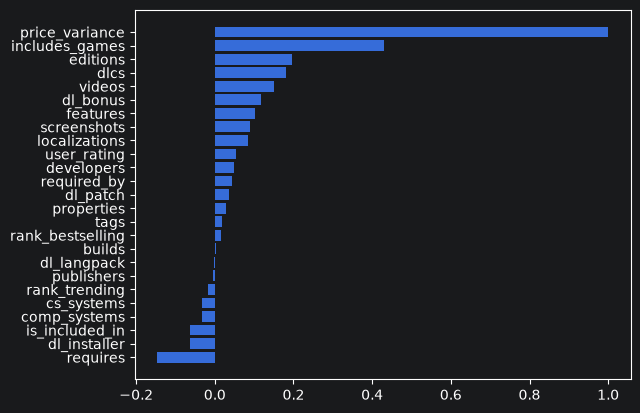

In [4]:
corr = corr.with_columns(feature=pl.Series(corr.columns)).sort("price_variance")
plt.barh(corr["feature"], corr["price_variance"]);